In [ ]:
!pip install -q pytorch-fid roboflow zenodo-get

from roboflow import Roboflow
from google.colab import userdata

# cylinder
rf = Roboflow(api_key=userdata.get("ROBOFLOW"))
project = rf.workspace("yeesonmin-naver-com").project("cylider2")
dataset = project.version("6").download("yolov7")

# KLSG
project = rf.workspace("object-detect-ury2h").project("sonar_detect")
dataset = project.version("1").download("yolov7")

# SDVDs
!zenodo_get 18268201
!unzip -q /content/AJaszcz/SDVDs-Sonar-Drowned-Victim-Datasets-v2.0.2.zip

!mv /content/AJaszcz-SDVDs-Sonar-Drowned-Victim-Datasets-f9eb4b5/SDVDs/ExtendedSDVD/ /content/
!rm -rf /content/AJaszcz*

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cylider2-6 in yolov7pytorch:: 100%|██████████| 968/968 [00:00<00:00, 2053.90it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to sonar_detect-1 in yolov7pytorch:: 100%|██████████| 1174/1174 [00:00<00:00, 6726.54it/s]


INFO: Output directory: /content
INFO: Title: SDVDs – Sonar Drowned Victim Datasets
INFO: Total size: 75.3 MB
INFO: Number of files: 1
SUCCESS: All specified files have been processed.


## Vanilla diffusion

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from pathlib import Path
from PIL import Image
import shutil
import glob
import os

from dataclasses import dataclass
from datasets import Dataset

import torch.nn.functional as F
from torchvision import transforms
import torch

from diffusers import UNet2DModel, DDPMScheduler, DDPMPipeline
from accelerate import Accelerator
from accelerate.utils import ProjectConfiguration
from diffusers.optimization import get_cosine_schedule_with_warmup

device = "cuda" if torch.cuda.is_available() else "cpu"

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


## Filter only cropped SSS

In [ ]:
klsg_selected_id = [
    44, 45, 130, 144, 155, 156, 165, 171, 175, 178, 180, 182, 190, 199, 201, 204, 205, 208, 209, 222, 226, 246, 249, 251,
    252, 260, 269, 273, 297, 311, 314, 322, 337, 340, 343, 346, 347, 348, 349, 355, 358, 361, 365, 369, 370, 371, 377,
    391, 392, 397, 399, 400, 401, 404, 405, 406, 413, 417, 425, 428, 437, 440, 456, 468, 470, 476, 481, 508, 524, 526,
    556, 577, 593, 601, 609, 615, 617, 619, 653, 655, 656, 657, 671, 673, 676, 679, 683,
    # validation
    16, 127, 132, 189, 191, 195, 197, 217, 223, 225, 356, 368, 375, 402, 411, 421, 453, 455, 497, 503, 531, 533, 562,
    573, 605, 616, 665, 675, 678,
    # test
    142, 157, 263, 352, 357, 436, 505, 610, 686
]

source_base_dir = '/content/sonar_detect-1'
destination_dir = 'klsg_full-sss'

images_destination_dir = os.path.join(destination_dir, 'images')
labels_destination_dir = os.path.join(destination_dir, 'labels')

os.makedirs(images_destination_dir, exist_ok=True)
os.makedirs(labels_destination_dir, exist_ok=True)

print(f"Copying selected KLSG images and labels to '{destination_dir}'...")
move_count = 0
for klsg_id in klsg_selected_id:
    # Format the ID to a 6-digit string
    id_str = f"{klsg_id:06d}"

    # Search in train, valid, test subdirectories
    for split in ['train', 'valid', 'test']:
        images_source_path_base = os.path.join(source_base_dir, split, 'images', f"{id_str}*")
        labels_source_path_base = os.path.join(source_base_dir, split, 'labels', f"{id_str}*")

        # Use glob to find image files
        found_images = glob.glob(images_source_path_base + ".jpg") + glob.glob(images_source_path_base + ".png")

        for image_path in found_images:
            if os.path.exists(image_path):
                # Construct corresponding label path
                base_filename = os.path.splitext(os.path.basename(image_path))[0]
                label_path = os.path.join(source_base_dir, split, 'labels', f"{base_filename}.txt")

                if os.path.exists(label_path):
                    image_dest_path = os.path.join(images_destination_dir, os.path.basename(image_path))
                    label_dest_path = os.path.join(labels_destination_dir, os.path.basename(label_path))

                    shutil.move(image_path, image_dest_path)
                    shutil.move(label_path, label_dest_path)
                    move_count += 1

print(f"Finished moving. Total {move_count} image/label pairs moved to '{destination_dir}'.")

Copying selected KLSG images and labels to 'klsg_full-sss'...
Finished moving. Total 125 image/label pairs moved to 'klsg_full-sss'.


In [ ]:
victim_images = glob.glob("/content/ExtendedSDVD/*/images/*")
victim_images = [path for path in victim_images if "left_" in os.path.basename(path) or "right_" in os.path.basename(path)]

train_victim = victim_images[ :int(0.8 * len(victim_images)) ]
valid_victim = victim_images[int(0.8 * len(victim_images)): ]
len(train_victim), len(valid_victim)

(144, 37)

In [ ]:
dest_train = '/content/sonar_detect-1/train/images'
dest_val = '/content/sonar_detect-1/valid/images'
for path in train_victim:
    fname = os.path.basename(path)
    dest_path = os.path.join(dest_train, fname)
    shutil.copy(path, dest_path)

for path in valid_victim:
    fname = os.path.basename(path)
    dest_path = os.path.join(dest_val, fname)
    shutil.copy(path, dest_path)

!mv /content/sonar_detect-1/test/images/* /content/sonar_detect-1/valid/images/
!rm -rf /content/sonar_detect-1/test/

## Diffusion

### Data & setup

In [ ]:
@dataclass
class TrainingConfig:
    image_size = 128
    train_batch_size = 16
    eval_batch_size = 16
    num_epochs = 500
    num_training_steps = 1000
    gradient_accumulation_steps = 2
    learning_rate = 1e-4
    lr_warmup_steps = 500
    save_image_epochs = 10
    save_model_epochs = 50
    mixed_precision = 'fp16'  # `no` for float32, `fp16` for automatic mixed precision
    output_dir = 'ddpm-cylinder'
    overwrite_output_dir = True
    seed = 3407

config = TrainingConfig()

torch.Size([16, 3, 128, 128])


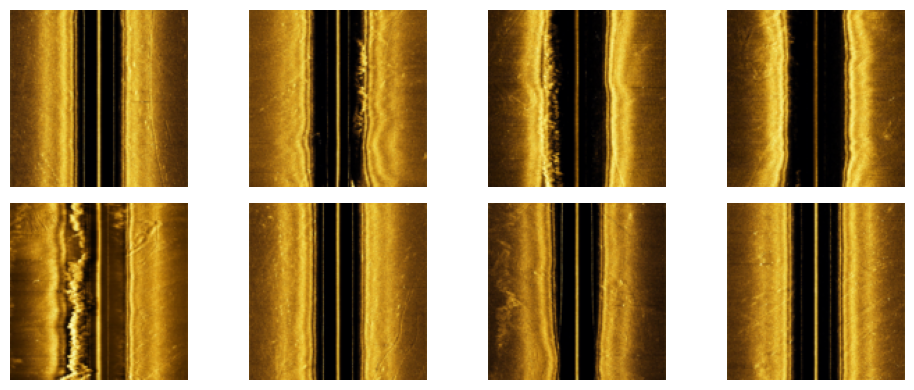

In [ ]:
train_dataset = Dataset.from_dict({"image": train_df['img_path'].tolist()})
val_dataset = Dataset.from_dict({"image": test_df['img_path'].tolist()})

preprocess = transforms.Compose(
    [
        transforms.Resize((config.image_size, config.image_size)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5]),
    ]
)

def transform(examples):
    images = [preprocess(Image.open(image).convert("RGB")) for image in examples["image"]]
    return {"images": images}

train_dataset.set_transform(transform)
val_dataset.set_transform(transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=config.train_batch_size, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=config.eval_batch_size, shuffle=False)

for inputs in train_loader:
    print(inputs['images'].shape)
    break

plt.subplots(2, 4, figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(inputs['images'][i].permute(1, 2, 0) * 0.5 + 0.5)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Architecture

In [ ]:
model = UNet2DModel(
    sample_size=config.image_size,  # the target image resolution
    in_channels=3,  # the number of input channels, 3 for RGB images
    out_channels=3,  # the number of output channels
    layers_per_block=2,  # how many ResNet layers to use per UNet block
    block_out_channels=(128, 128, 256, 256, 512, 512),  # the number of output channes for each UNet block
    down_block_types=(
        "DownBlock2D",  # a regular ResNet downsampling block
        "DownBlock2D",
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",  # a ResNet downsampling block with spatial self-attention
        "DownBlock2D",
    ),
    up_block_types=(
        "UpBlock2D",  # a regular ResNet upsampling block
        "AttnUpBlock2D",  # a ResNet upsampling block with spatial self-attention
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D"
      ),
)

sample_image = train_dataset[0]['images'].unsqueeze(0)
print('Output shape:', model(sample_image, timestep=0).sample.shape)

Output shape: torch.Size([1, 3, 128, 128])


In [ ]:
noise_scheduler = DDPMScheduler(num_train_timesteps=config.num_training_steps)
optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate)
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=config.lr_warmup_steps,
    num_training_steps=config.num_training_steps,
)

def make_grid(images, rows, cols):
    w, h = images[0].size
    grid = Image.new('RGB', size=(cols*w, rows*h))
    for i, image in enumerate(images):
        grid.paste(image, box=(i%cols*w, i//cols*h))
    return grid

def evaluate(config, epoch, pipeline):
    with torch.inference_mode():
        images = pipeline(
            batch_size=config.eval_batch_size,
            generator=torch.Generator(device=pipeline.device).manual_seed(config.seed),
        ).images

    image_grid = make_grid(images, rows=4, cols=4)
    test_dir = os.path.join(config.output_dir, "samples")
    os.makedirs(test_dir, exist_ok=True)
    image_grid.save(f"{test_dir}/{epoch+1:04d}.png")


def train_loop(config, model, noise_scheduler, optimizer, train_dataloader, lr_scheduler):
    # Initialize accelerator and tensorboard logging
    logging_dir = os.path.join(config.output_dir, "logs")
    accelerator_project_config = ProjectConfiguration(project_dir=config.output_dir, logging_dir=logging_dir)
    accelerator = Accelerator(
        mixed_precision=config.mixed_precision,
        gradient_accumulation_steps=config.gradient_accumulation_steps,
        log_with="tensorboard",
        project_config=accelerator_project_config,
    )

    # Prepare everything
    model, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
        model, optimizer, train_dataloader, lr_scheduler
    )

    model.train()
    global_step = 0

    for epoch in range(config.num_epochs):
        progress_bar = tqdm(total=len(train_dataloader), disable=not accelerator.is_local_main_process)
        progress_bar.set_description(f"Epoch {epoch+1}")

        for step, batch in enumerate(train_dataloader):
            clean_images = batch["images"]
            # Sample noise to add to the images
            noise = torch.randn_like(clean_images)
            bs = clean_images.shape[0]

            # Random timestep per image
            timesteps = torch.randint(
                0,
                noise_scheduler.config.num_train_timesteps,
                (bs,),
                device=clean_images.device,
                dtype=torch.long,
            )

            # Forward diffusion (add noise)
            noisy_images = noise_scheduler.add_noise(clean_images, noise, timesteps)

            with accelerator.accumulate(model):
                # Use autocast for mixed precision runs
                with accelerator.autocast():
                    # Predict the noise residual
                    noise_pred = model(noisy_images, timesteps, return_dict=False)[0]
                    loss = F.mse_loss(noise_pred, noise)

                accelerator.backward(loss)

                # IMPORTANT: only unscale/clip when we're about to step
                if accelerator.sync_gradients:
                    accelerator.clip_grad_norm_(model.parameters(), 1.0)

                optimizer.step()
                lr_scheduler.step()
                optimizer.zero_grad()

            progress_bar.update(1)
            logs = {"loss": loss.detach().item(), "lr": lr_scheduler.get_last_lr()[0], "step": global_step}
            progress_bar.set_postfix(**logs)
            accelerator.log(logs, step=global_step)
            global_step += 1

        # Sample & save after each epoch
        if accelerator.is_main_process:
            pipeline = DDPMPipeline(unet=accelerator.unwrap_model(model), scheduler=noise_scheduler)
            if (epoch + 1) % config.save_image_epochs == 0 or epoch == config.num_epochs - 1:
                evaluate(config, epoch, pipeline)
                pipeline.save_pretrained(f"ddpm-cylinder/checkpoint-{epoch+1}")

### Execution

In [ ]:
from accelerate import notebook_launcher
args = (config, model, noise_scheduler, optimizer, train_loader, lr_scheduler)

notebook_launcher(train_loop, args, num_processes=1)

Launching training on one GPU.


  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

... (156 outputs left out)

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [ ]:
pipeline = DDPMPipeline.from_pretrained("ddpm-cylinder/checkpoint-140").to("cuda")

def inference(dataloader, pipeline):
    infer_images = []
    for batch in tqdm(dataloader):
        # In a real inference scenario, you might start with noise
        images = batch["images"]
        noise = torch.randn_like(images)
        bs = images.shape[0]

        # Random timestep per image
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bs,),
            device=images.device, dtype=torch.long,)

        # Forward diffusion (add noise)
        noisy_images = noise_scheduler.add_noise(images, noise, timesteps)
        with torch.inference_mode():
            # Generate images from noisy inputs
            generated_images = pipeline(
                batch_size=noisy_images.shape[0],
                generator=torch.manual_seed(config.seed),
            ).images
        infer_images.extend(generated_images)
    return infer_images

# inference
generated_images = inference(val_loader, pipeline)
plt.subplots(2, 4, figsize=(10, 4))
for i in range(min(8, len(generated_images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(generated_images[i]) # PIL Images are displayed directly
    plt.axis('off')
plt.tight_layout()
plt.show()

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 